## Testing how well the Phoenix ODE model can fit 
E.g. when more genes, more densely connected, etc




In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
from pathlib import Path
from halcyon.Simulators.GNWSimRunner import GNWSimRunner
from halcyon.Datasets.ExpressionDataWithConditions import ExpressionDataWithConditions
from halcyon.Models.NeuralODE import PhoenixOnlyAddLayers, PhoenixAddAndProdLayers
from halcyon.Trainer import Trainer
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from halcyon.Datasets.ExpressionData import ExpressionData

# Some quick code for the poster

Loading specified settings: ../setting_files/gnw_testing_runs_settings.txt
Done
Start network creation of type MODULAR_SCALEFREE
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: ~(Node_0~Node_2) + ~(Node_3*Node_1)
my_network: Node_1: (Node_0*Node_1~Node_3) + (Node_4) + (Node_2)
my_network: Node_2: ~(Node_0) + ~(Node_1) + ~(Node_2)
my_network: Node_3: (Node_1*Node_4*Node_3)
my_network: Node_4: ~(Node_1) + ~(Node_4) + ~(Node_3)
my_network: Node_5: (Node_0)
Writing file /lustre/BIF/nobackup/noord087/phd/HALCYON/notebooks/../data/figure_for_poster/genes_6_modules_2_sparsity_0.01/my_network.xml

Thomas Schaffter (thomas.schaff...@gmail.com)
Daniel Marbach (daniel.marb...@gmail.com)
Gilles Roulet (gilles.rou...@gmail.com)

http://tschaffter.ch/projects/gnw


<Axes: xlabel='Time', ylabel='Expression'>

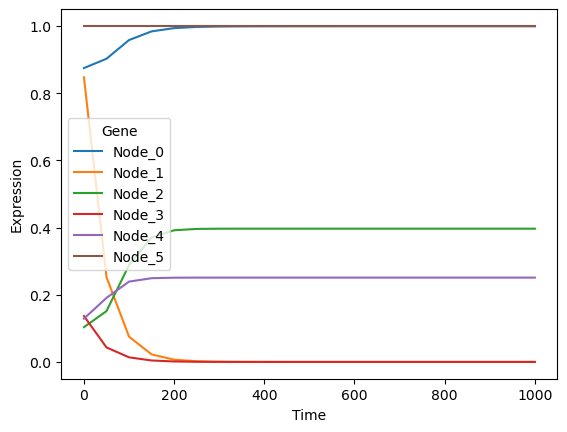

In [ ]:
gnw_sim = GNWSimRunner(
    settings_path=Path("../setting_files/gnw_testing_runs_settings.txt"),
)
nr_genes = 6
sparsity = .01
nr_modules = 2
generated_data_path = Path("../data/figure_for_poster") / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
generated_data_path.mkdir(parents=True, exist_ok=True)
network_name = 'my_network'
gnw_sim.run_simulation(
    n_genes=nr_genes,
    sparsity=sparsity,
    num_modules=nr_modules,
    network_name=network_name,
    output_path=generated_data_path,
)
df_double_ko = pd.read_csv(
    generated_data_path / f'{network_name}_nonoise_dualknockout_timeseries.tsv',
    sep='\t', index_col=0, header=0, nrows=21)

ExpressionData(df_double_ko.T).plot_expressions()



<Axes: xlabel='Time', ylabel='Expression'>

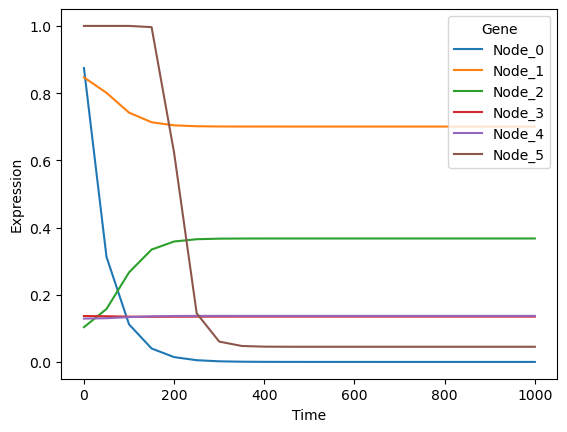

In [31]:
df_single_ko = pd.read_csv(
    generated_data_path / f'{network_name}_nonoise_knockout_timeseries.tsv',
    sep='\t', index_col=0, header=0, nrows=21)

ExpressionData(df_single_ko.T).plot_expressions()

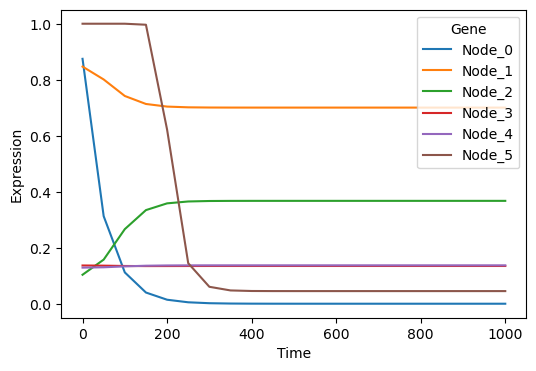

In [39]:
fig, ax = plt.subplots(figsize=(6, 4))
ExpressionData(df_single_ko.T).plot_expressions(axis=ax)
fig.savefig(generated_data_path /"single_ko.svg")

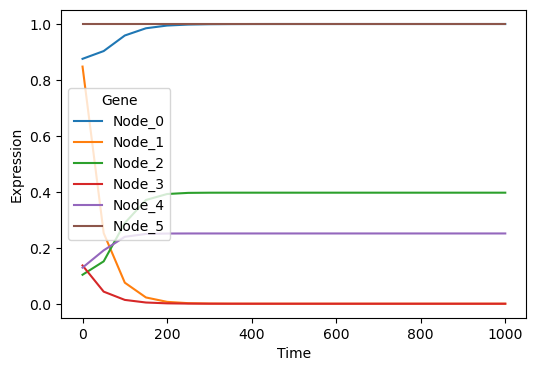

In [37]:
fig, ax = plt.subplots(figsize=(6, 4))
ExpressionData(df_double_ko.T).plot_expressions(axis=ax)
fig.savefig(generated_data_path /"double_ko.svg")

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [ ]:
import logging


logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

In [ ]:
results = []
nr_training_steps = 100
for nr_genes in [32]: #, 20, 50, 100]:
    for nr_modules in [4]: #, 5, 10]:
        for sparsity in [0.1,]: # 0.25, 0.5]:
            gnw_sim = GNWSimRunner(
                settings_path=Path("../setting_files/gnw_testing_runs_settings.txt"),
            )
            generated_data_path = Path("../data/fitting_on_multiple_sim_settings") / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
            generated_data_path.mkdir(parents=True, exist_ok=True)
            network_name = 'my_network'
            gnw_sim.run_simulation(
                n_genes=nr_genes,
                sparsity=sparsity,
                num_modules=nr_modules,
                network_name=network_name,
                output_path=generated_data_path,
            )
            expressions =  ExpressionDataWithConditions.from_genenetweaver_ko_timeseries_output(
                generated_data_path / f'{network_name}_nonoise_knockout_timeseries.tsv'
            )
            expressions.scale_time_series()
            model = PhoenixAddAndProdLayers(expressions.genes, expressions.all_environments, hidden_size=16)
            my_trainer = Trainer(model, expressions, batch_size=32, optimizer_kwargs={'lr': .1})
            my_trainer.train(nr_training_steps)
            my_trainer.loss_history
            final_loss = my_trainer.loss_history[-1]
            results.append({
                "nr_genes": nr_genes,
                "nr_modules": nr_modules,
                "sparsity": sparsity,
                "final_loss": final_loss,
            })
            print(f"Finished fitting for genes: {nr_genes}, modules: {nr_modules}, sparsity: {sparsity}, final loss: {final_loss}")

In [ ]:
my_trainer.train(nr_training_steps)

In [ ]:
# Assuming `results` is a list of dicts
df = pd.DataFrame(results)

# Pivot so genes = columns, modules = rows
heatmap_data = df.pivot_table(
    index="nr_modules",
    columns="nr_genes",
    values="final_loss",
    aggfunc="mean"
)

sns.heatmap(
    heatmap_data,
    annot=True,        # write values in the cells
    fmt=".5f",         # number format
    cmap="viridis",    # colour map
    cbar_kws={"label": "Final Loss"}
)
plt.xlabel("Number of Genes")
plt.ylabel("Number of Modules")
plt.title("Final Loss Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
my_trainer.plot_fit_vs_real(top_n=5)